In [1]:
from transformers import AutoModelForCausalLM, AutoTokenizer
import torch

model_id = "Qwen/Qwen3.5-2B"

tokenizer = AutoTokenizer.from_pretrained(model_id)
model = AutoModelForCausalLM.from_pretrained(model_id, device_map="cuda", dtype=torch.bfloat16)

config.json:   0%|          | 0.00/2.91k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/16.7k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/6.72M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/3.35M [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 12.8MB            

...

chat_template.jinja:   0%|          | 0.00/7.75k [00:00<?, ?B/s]

model.safetensors.index.json:   0%|          | 0.00/64.5k [00:00<?, ?B/s]

model.safetensors-00001-of-00001.safeten(…): reconstructing file:   0%|          |  0.00B / 4.55GB            

model.safetensors-00001-of-00001.safeten(…): downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/320 [00:00<?, ?it/s]

In [1]:
from transformers import AutoModelForCausalLM, AutoTokenizer
import torch
model_id = "ibm-granite/granite-guardian-3.1-2b"
tokenizer = AutoTokenizer.from_pretrained(model_id)
model = AutoModelForCausalLM.from_pretrained(model_id, device_map="cuda", dtype=torch.bfloat16)

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/362 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/132 [00:00<?, ?B/s]

Total rows:        848
Valid drift labels:848
Missing/invalid:   0

Class distribution
------------------
 no:   647  ( 76.30%)
yes:   201  ( 23.70%)

Imbalance
---------
Majority : minority = 3.22 : 1
Positive ('yes') rate = 23.70%

Assignment-level distribution
-----------------------------
Assignments total:                  152
Assignments containing drift=yes:   85
Assignments with ≥1 positive:       55.92%


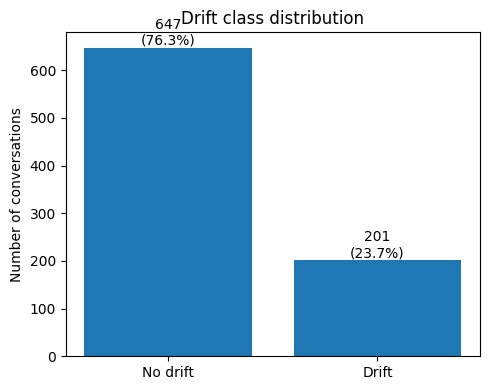

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

# Change this to your dataset CSV or folder of CSVs
INPUT_PATH = Path("../lab_exercise_dataset")
LABEL_COL = "drift"

# Load data
if INPUT_PATH.is_file():
    df = pd.read_csv(INPUT_PATH)
else:
    files = sorted(INPUT_PATH.glob("*.csv"))
    if not files:
        raise FileNotFoundError(f"No CSV files found in {INPUT_PATH}")
    df = pd.concat([pd.read_csv(f) for f in files], ignore_index=True)

if LABEL_COL not in df.columns:
    raise KeyError(f"'{LABEL_COL}' not found. Available columns: {list(df.columns)}")

# Clean labels
labels = df[LABEL_COL].astype(str).str.strip().str.lower()
valid = labels.isin(["yes", "no"])

print(f"Total rows:        {len(df):,}")
print(f"Valid drift labels:{valid.sum():,}")
print(f"Missing/invalid:   {(~valid).sum():,}")

labels = labels[valid]

counts = labels.value_counts().reindex(["no", "yes"], fill_value=0)
percentages = counts / len(labels) * 100

print("\nClass distribution")
print("------------------")
for label in ["no", "yes"]:
    print(f"{label:>3}: {counts[label]:>5,}  ({percentages[label]:6.2f}%)")

minority = counts.min()
majority = counts.max()

print("\nImbalance")
print("---------")
if minority > 0:
    print(f"Majority : minority = {majority / minority:.2f} : 1")
else:
    print("One class has zero examples.")

print(f"Positive ('yes') rate = {percentages['yes']:.2f}%")

# Assignment-level view, if available
if "assignment_id" in df.columns:
    valid_df = df.loc[valid].copy()
    valid_df["_drift"] = labels.values

    positive_df = valid_df[valid_df["_drift"] == "yes"]

    print("\nAssignment-level distribution")
    print("-----------------------------")
    print(f"Assignments total:                  {valid_df['assignment_id'].nunique():,}")
    print(f"Assignments containing drift=yes:   {positive_df['assignment_id'].nunique():,}")

    if valid_df["assignment_id"].nunique():
        pct = (
            positive_df["assignment_id"].nunique()
            / valid_df["assignment_id"].nunique()
            * 100
        )
        print(f"Assignments with ≥1 positive:       {pct:.2f}%")

# Plot
fig, ax = plt.subplots(figsize=(5, 4))
bars = ax.bar(["No drift", "Drift"], [counts["no"], counts["yes"]])

ax.set_ylabel("Number of conversations")
ax.set_title("Drift class distribution")

for bar, count, pct in zip(
    bars,
    [counts["no"], counts["yes"]],
    [percentages["no"], percentages["yes"]]
):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{count:,}\n({pct:.1f}%)",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()